In [ ]:
#This has the examples for every method we try

(2,)
(2, 2)
[ 0.22075312 -0.05011473]
[[ 0.02058824 -0.00588235]
 [-0.00588235  0.00882353]]


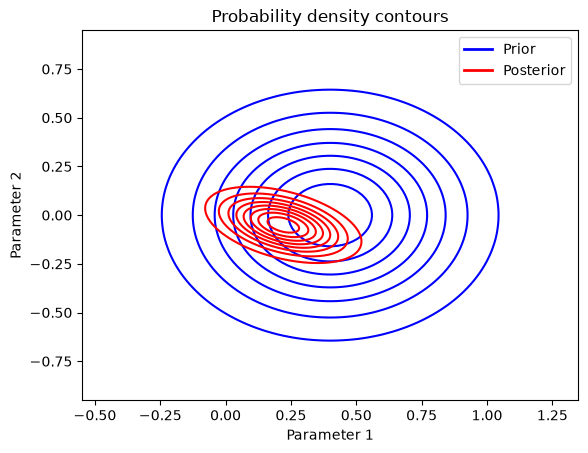

0.029411764705882353


In [ ]:
##Test Example for Analytical Computation
from BayesianMVLinGaussIP import *
import matplotlib.pyplot as plt
import scipy.stats as ss
import numpy as np
prior_mean = np.array([0.4,0]) #Prior mean vector
prior_cov = np.array([[0.1, 0.0],
          [0.0, 0.1]]) #prior covariance vector

A = np.array([[2,3],[-1,2]]) #2D example
dim = 2

noise_cov = 0.1 * np.identity(2) #noise covariance
c = BayesianMVLinGaussIP(prior_mean, prior_cov, dim, noise_cov)

rng = np.random.default_rng(seed=123)

parameter_sample = rng.multivariate_normal(prior_mean, prior_cov)
noise_sample = rng.multivariate_normal(np.zeros(2), noise_cov)

y = A @ parameter_sample + noise_sample


Gamma_posterior, mu_posterior = c.posterior_calculations(A=A, y=y)
print(mu_posterior.shape)
print(Gamma_posterior.shape)
print(mu_posterior)
print(Gamma_posterior)
trace_actual = np.trace(Gamma_posterior)
print(trace_actual)

fig, ax = plt.subplots()

_, prior_handle = c.plot_distribution_contour(mean=prior_mean,cov=prior_cov, ax=ax, label = 'Prior', color = 'blue')
_, posterior_handle = c.plot_distribution_contour(mean=mu_posterior,cov=Gamma_posterior, ax = ax, label = 'Posterior', color = 'red')

ax.legend(handles = [prior_handle, posterior_handle])
plt.show()



fig.savefig('TruePosteriorContour.png', dpi=300, transparent=True, bbox_inches='tight')






Exact posterior mean is: [ 0.22075312 -0.05011473]
Exact posterior cov is: [[ 0.02058824 -0.00588235]
 [-0.00588235  0.00882353]]
Rep 0: chain too short to estimate tau
(800, 2)
[ 0.2381741  -0.04332157]
[[ 0.01817427 -0.00427591]
 [-0.00427591  0.00794274]]
Mean error emcee: 0.018698598612274818
0.026117012489330356
Trace error emcee: 0.0032947522165519966
Exact posterior mean is: [ 0.22075312 -0.05011473]
Exact posterior cov is: [[ 0.02058824 -0.00588235]
 [-0.00588235  0.00882353]]
Rep 0: tau = [24.52472304 37.01994735]
(9800, 2)
[ 0.22194549 -0.0399105 ]
[[ 0.01941272 -0.00623521]
 [-0.00623521  0.00905981]]
Mean error emcee: 0.010273659614729171
0.028472532334899277
Trace error emcee: 0.0009392323709830758
Exact posterior mean is: [ 0.22075312 -0.05011473]
Exact posterior cov is: [[ 0.02058824 -0.00588235]
 [-0.00588235  0.00882353]]
Rep 0: tau = [45.69468497 44.63719779]
(99800, 2)
[ 0.22116932 -0.04940193]
[[ 0.02068694 -0.00586194]
 [-0.00586194  0.00891805]]
Mean error emcee: 

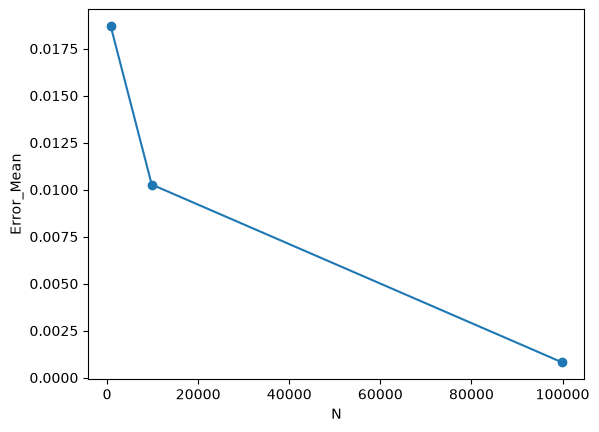

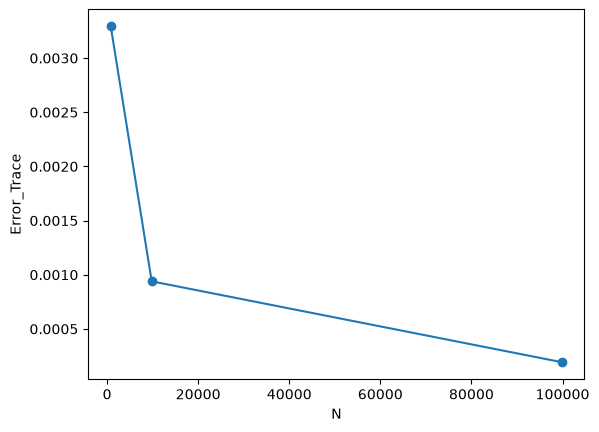

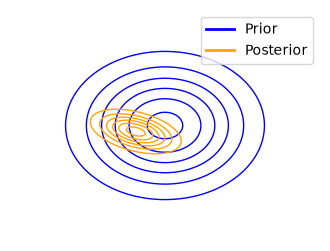

In [2]:
#Test Example MCMC
import emcee
from EMCEE_MCMC import *
ndim = 2
nwalkers = 4

mcmc = EMCEE_MCMC(prior_mean, prior_cov,ndim, nwalkers,noise_cov)

N_values_emcee = []
mean_errors_emcee = []
trace_errors_emcee = []

data = mcmc.generate_data(prior_mean=prior_mean, prior_cov= prior_cov, A = A, noise_cov = noise_cov, rng = rng)

for nsteps in [250, 2500, 25000]:
    results, mean_errors_emcee1, trace_errors_emcee1 = mcmc.run_all(A,nsteps)
    samples = results[0]
    print(samples.shape)
    emcee_mean = np.mean(samples,axis = 0)
    emcee_cov = np.cov(samples.T)
    print(emcee_mean)
    print(emcee_cov)
    mean_error_emcee = np.linalg.norm(emcee_mean - mu_posterior)
    print("Mean error emcee:", mean_error_emcee)
    
    N_emcee = samples.shape[0]
    N_values_emcee.append(N_emcee)
    mean_errors_emcee.append(mean_error_emcee)
    trace_emcee = np.trace(emcee_cov)
    print(trace_emcee)
    trace_error_emcee = np.linalg.norm(trace_emcee - trace_actual)
    print("Trace error emcee:", trace_error_emcee)
    trace_errors_emcee.append(trace_error_emcee)

plt.plot(N_values_emcee, mean_errors_emcee, marker = 'o')
plt.xlabel("N")
plt.ylabel('Error_Mean')
plt.show()

plt.plot(N_values_emcee, trace_errors_emcee, marker = 'o')
plt.xlabel("N")
plt.ylabel('Error_Trace')
plt.show()


fig, ax = plt.subplots(figsize=(4, 3))

_, prior_handle_mcmc = mcmc.plot_distribution_contour(mean=prior_mean,cov=prior_cov, ax=ax, label = 'Prior', color = 'blue')
_, posterior_handle_mcmc = mcmc.plot_distribution_contour(mean=emcee_mean,cov=emcee_cov, ax = ax, label = 'Posterior', color = 'orange')

ax.legend(handles = [prior_handle_mcmc, posterior_handle_mcmc])
plt.savefig("MCMC.png", dpi=300, bbox_inches="tight")
plt.show()

Exact posterior mean: [ 0.22075312 -0.05011473]
Exact posterior cov: [[ 0.02058824 -0.00588235]
 [-0.00588235  0.00882353]]
(Array(-61.395424, dtype=float32), Array([  77425953, 1216862794], dtype=uint32))
step 0, loss: 108.2222900390625
(Array(-50.307312, dtype=float32), Array([  77425953, 1216862794], dtype=uint32))
[[ 0.84454024 -0.05507474]
 [-0.05507474  0.83747816]]
[0.03574852 0.00210287]
mean_error_VI: 0.19223262
N=: 1000
trace_error_VI: 1.6526066345327042
(Array(-61.395424, dtype=float32), Array([  77425953, 1216862794], dtype=uint32))
step 0, loss: 108.2222900390625
step 500, loss: 61.607879638671875
(Array(-15.830238, dtype=float32), Array([  77425953, 1216862794], dtype=uint32))
[[ 0.29731035 -0.09379239]
 [-0.09379239  0.30027857]]
[ 0.21016538 -0.02962965]
mean_error_VI: 0.023059463
N=: 10000
trace_error_VI: 0.5681771320455214
(Array(-61.395424, dtype=float32), Array([  77425953, 1216862794], dtype=uint32))
step 0, loss: 108.2222900390625
step 500, loss: 61.60787963867187

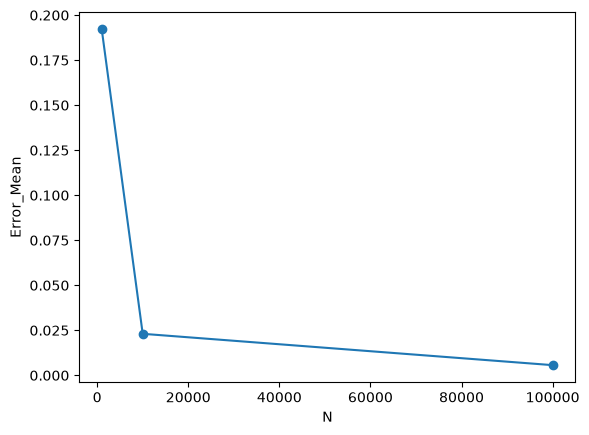

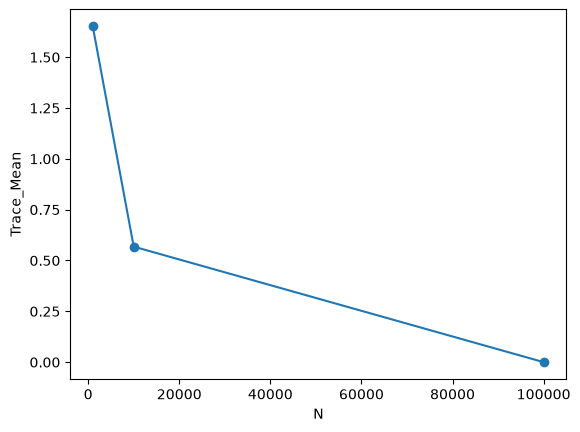

Optimized_mu for maximum budget: [ 0.21536636 -0.04839196]
Optimized_cov for maximum budget: [[ 0.02063706 -0.00587335]
 [-0.00587335  0.00886208]]


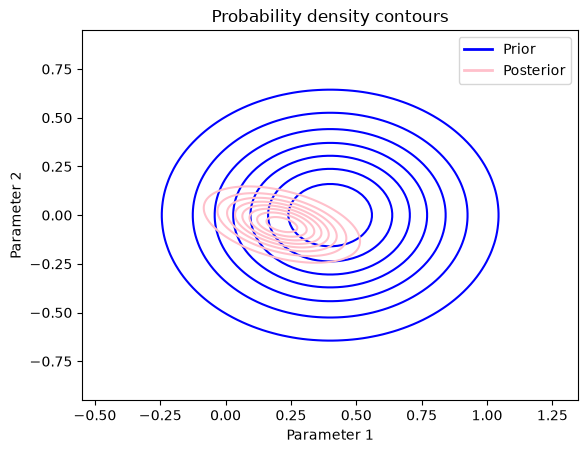

10000


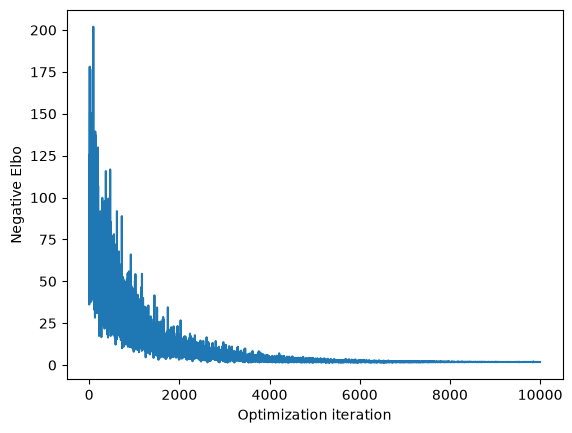

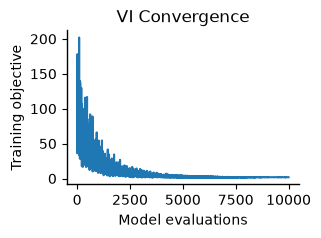

In [3]:
#Test example with Full rank variational inference
import jax
import jax.numpy as jnp
from FullRankMVNVI import *
import numpy as np
import optax
import matplotlib.pyplot as plt
from BayesianMVLinGaussIP import BayesianMVLinGaussIP

key = jax.random.PRNGKey(1)
prior_mean = np.array([0.4,0]) #Prior mean vector
prior_cov = np.array([[0.1, 0.0],
          [0.0, 0.1]]) #prior covariance vector

A = np.array([[2,3],[-1,2]],dtype=float)
dim = 2

noise_cov = 0.1 * np.identity(2)

prior_cov_inv = jnp.linalg.inv(prior_cov)
noise_cov_inv = jnp.linalg.inv(noise_cov)

rng = np.random.default_rng(seed=123)
VI = FullRankVI(dim, prior_mean=prior_mean,prior_cov=prior_cov,noise_cov=noise_cov) #The class is here

params = VI.init_params() #params are mu and raw_L


N_values_VI = []
mean_errors_VI = []
trace_errors_VI = []

data = VI.generate_data(
                    A=A,
                    prior_mean=VI.prior_mean,
                    prior_cov=VI.prior_cov,
                    noise_cov=VI.noise_cov,
                    rng=rng
                )

model = BayesianMVLinGaussIP(prior_mean=prior_mean, prior_cov = prior_cov, dim = 2, noise_cov=noise_cov) 
                            # TNP: True posterior for comparison to computed one.
    
    
    


exact_posterior_cov, exact_posterior_mean  = model.posterior_calculations(
                                            A=A,
                                            y=data)

print("Exact posterior mean:", exact_posterior_mean)
print("Exact posterior cov:", exact_posterior_cov)

for n_steps in [100, 1000, 10000]:

    

    trace_actual = np.trace(exact_posterior_cov)
    
    elbo_initial = VI.elbo(
        key,
        params,
        A,
        data,
        prior_mean,
        prior_cov_inv,
        noise_cov_inv,
        n_samples = 10) #calculating the Elbo

    print(elbo_initial)

    optimizer = optax.adam(learning_rate=1e-3)
    #Optimization part: 
    optimized_params, opt_state, loss_history, model_eval_history = VI.fit(
        key = key,
        params = params, 
        optimizer = optimizer,
        A =A, 
        y =data, 
        prior_mean = prior_mean, 
        prior_cov_inv = prior_cov_inv, 
        noise_cov_inv = noise_cov_inv,
        n_steps=n_steps)

    elbo_optimized = VI.elbo(
        key,
        optimized_params,
        A,
        data,
        prior_mean,
        prior_cov_inv,
        noise_cov_inv,
        n_samples=10
    )

    print(elbo_optimized)

    L = VI.make_L(optimized_params["raw_L"]) 
    optimized_covariance = L @ L.T
    optimized_mu = optimized_params["mu"]

    print(optimized_covariance)
    print(optimized_mu)
    mean_error_VI = np.linalg.norm(optimized_mu - exact_posterior_mean)
    print("mean_error_VI:", mean_error_VI)
    n_samples = 10
    N = n_samples * n_steps
    print("N=:",N)
    N_values_VI.append(N)
    mean_errors_VI.append(mean_error_VI)

    trace_VI = np.trace(optimized_covariance)

    trace_error_VI = np.linalg.norm(trace_VI-trace_actual)
    print("trace_error_VI:", trace_error_VI)
    trace_errors_VI.append(trace_error_VI)



plt.plot(N_values_VI, mean_errors_VI, marker = 'o')
plt.xlabel("N")
plt.ylabel('Error_Mean')
plt.show()

plt.plot(N_values_VI, trace_errors_VI, marker = 'o')
plt.xlabel("N")
plt.ylabel('Trace_Mean')
plt.show()

print("Optimized_mu for maximum budget:", optimized_mu)
print("Optimized_cov for maximum budget:", optimized_covariance)

fig, ax = plt.subplots()


_, prior_handle_VI = VI.plot_distribution_contour(mean=prior_mean, cov = prior_cov,  ax=ax, label = 'Prior', color = 'blue')
_, posterior_handle_VI = VI.plot_distribution_contour(optimized_mu, optimized_covariance,  ax=ax, label = 'Posterior', color = 'pink')


ax.legend(handles = [prior_handle_VI, posterior_handle_VI])
plt.show()



plt.plot(loss_history)
plt.xlabel("Optimization iteration" )
plt.ylabel("Negative Elbo")

print(len(loss_history))

plt.figure(figsize=(3, 2)) 
plt.plot(model_eval_history, loss_history) 
plt.xlabel("Model evaluations") 
plt.ylabel("Training objective") 
plt.title("VI Convergence")
plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)

plt.gca().spines["left"].set_linewidth(1)
plt.gca().spines["bottom"].set_linewidth(1)

plt.savefig("vi_convergence.png", dpi=300, bbox_inches="tight")

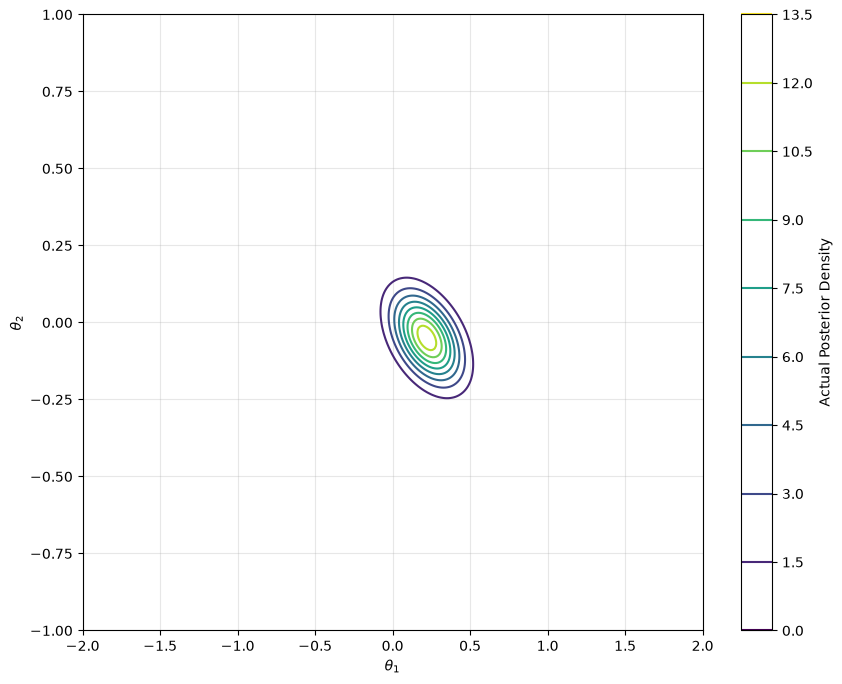

13.121364659750853


In [4]:
#Dual_Bayes_EX
from BayesianMVLinGaussIP import *
import matplotlib.pyplot as plt
import numpy as np
from Dual_Problem_Bayes_Class import *
sigma_val = 1 
rng = np.random.default_rng(seed=26021000)
prior_mean = np.array([0.4,0]) #Prior mean vector
prior_cov = np.array([[0.1, 0.0],
          [0.0, 0.1]]) #prior covariance vector

A = np.array([[2,3],[-1,2]])

noise_cov = 0.1 * np.identity(2)

theta1 = np.linspace(-2, 2, 350)
theta2 = np.linspace(-1, 1, 300)

dual_problem = Dual_Problem_Bayes_Class(prior_mean=prior_mean, prior_cov=prior_cov,ndim = 2, noise_cov=noise_cov)

#Get prior_samples
#prior_samples = Dual_Problem_Bayes_Class.sample_from_prior(prior_mean = prior_mean, prior_cov = prior_cov, N=N)
#posterior
data = dual_problem.data(prior_mean=prior_mean, prior_cov=prior_cov, A=A, noise_cov=noise_cov)

exact_posterior_cov, exact_posterior_mean = dual_problem.exact_posterior_parameters(A=A,data = data)
posterior_dist1 = dual_problem.exact_posterior(exact_posterior_mean=exact_posterior_mean, exact_posterior_cov=exact_posterior_cov)
#Actual posterior plot
dual_problem.plot_contour_meshgrid(theta1, theta2, posterior_dist1, "Actual Posterior Density")

T1, T2 = np.meshgrid(theta1, theta2, indexing="ij")
Z = posterior_dist1.pdf(np.stack([T1.ravel(), T2.ravel()], axis=-1))
Z = Z.reshape(T1.shape)
max_val = np.max(Z)
print(max_val)

[ 0.21699723 -0.05163482]
Dual Mean Error: 0.004051828600755053
[[ 0.01827151 -0.00536819]
 [-0.00536819  0.00791646]]
Dual Trace Error: 0.003223798355956743
[ 0.22181029 -0.05295398]
Dual Mean Error: 0.003029684510551269
[[ 0.0206383  -0.00580559]
 [-0.00580559  0.0086285 ]]
Dual Trace Error: 0.0001449658492992667
[ 0.22035307 -0.05009949]
Dual Mean Error: 0.0004003326489707373
[[ 0.02047239 -0.00587727]
 [-0.00587727  0.00882846]]
Dual Trace Error: 0.00011091190308605212


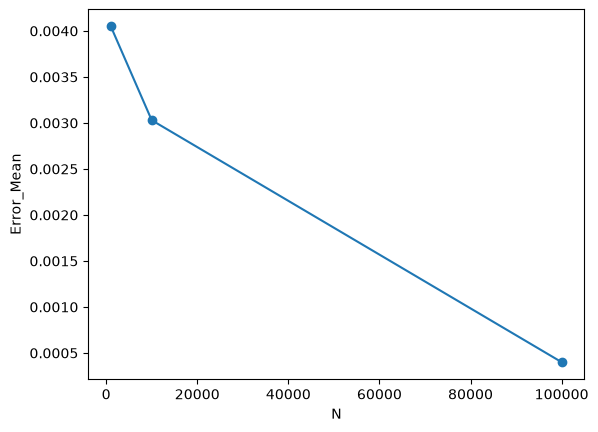

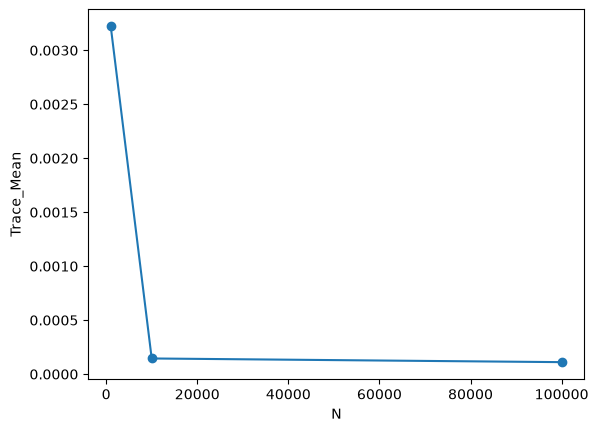

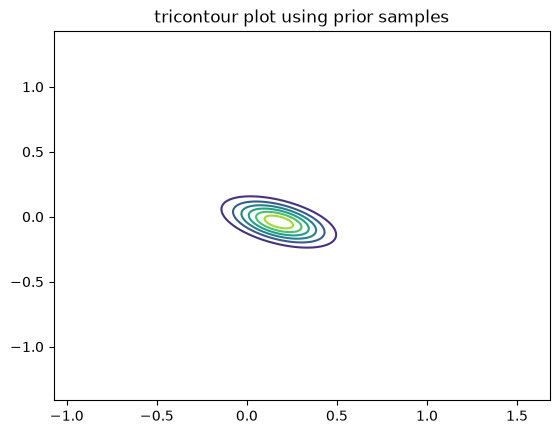

In [5]:
# The semi-analytic posterior with tricontour 

#Get prior_samples

#g_theta_samples2 = dual_problem.vectorized_log_likelihood(data, prior_samples, A, noise_cov)
#g_theta_samples2 = dual_problem.get_g_theta(data=data, A=A, noise_cov = noise_cov)
#dual_problem.plot_tricontour_prior(prior_samples=prior_samples,g_theta_samples2=g_theta_samples2)

budgets = [1000, 10000, 100000]
mean_errors_dual = []
trace_errors_dual = []



for budget in budgets:
    prior_samples_all = dual_problem.sample_from_prior(N=budget)
    prior_samples_one = prior_samples_all[0]
    g_theta_samples2 = dual_problem.get_g_theta(data=data, A=A, noise_cov=noise_cov, theta_samples=prior_samples_one)
    

 
   

    psi = dual_problem.psi_kl
    #result = dual_problem.get_result(g_theta_samples2=prior_samples, sigma_val = sigma_val, psi = psi)
    result = dual_problem.solve_saa_jax(g_theta_samples2, sigma_val, psi)



    semi_analytic_vals = dual_problem.semianalytic_vectorized(theta= prior_samples_one, data = data, A=A, noise_cov = noise_cov, result = result, sigma_val = sigma_val, psi=psi)
    #dual_problem.plot_tricontour_prior(prior_samples=prior_samples,g_theta_samples2=g_theta_samples2)


    post_mean = np.mean(prior_samples_one * semi_analytic_vals[:,None], axis = 0)
    print(post_mean)
    error_dual = np.linalg.norm(post_mean - mu_posterior)
    print("Dual Mean Error:", error_dual)

    mean_errors_dual.append(error_dual)
    
    centered = prior_samples_one - post_mean
    post_cov = np.mean(centered[:,:, None] * centered[:,None,:] * semi_analytic_vals[:,None,None],axis = 0)
    print(post_cov)
    trace_dual = np.trace(post_cov)

    trace_error_dual = np.linalg.norm(trace_dual-trace_actual)
    print("Dual Trace Error:", trace_error_dual)
    trace_errors_dual.append(trace_error_dual)

plt.figure()

plt.plot(budgets,mean_errors_dual, marker = 'o')
plt.xlabel("N")
plt.ylabel('Error_Mean')
plt.show()

plt.plot(budgets,trace_errors_dual, marker = 'o')
plt.xlabel("N")
plt.ylabel('Trace_Mean')
plt.show()



    


    

dual_problem.plot_tricontour_prior(prior_samples=prior_samples_one,g_theta_samples2=semi_analytic_vals)

#Maximizing the semi-analytic posterior or minimizing the - log_posterior
#theta0 = np.array(prior_mean)

#def neg_log_posterior(theta):
    
    #return -(
        #dual_problem.log_prior(theta) +
        #dual_problem.log_posterior(theta, data = data, A=A, noise_cov = noise_cov, result = result, sigma_val = sigma_val, psi = psi)
   #)



#def neg_posterior(theta):
   # return -dual_problem.posterior(
       # theta,
       # data=data,
      #  A=A,
       # noise_cov=noise_cov,
        #result=result,
        #sigma_val=sigma_val,
        #psi=psi
    #)
#theta0 = prior_mean

#res = minimize(
    #fun=neg_posterior,
    #x0=theta0,
   # method="BFGS"
#)

#print("Optimal theta:", res.x)
#print("Minimum objective value:", res.fun)
#print("Success:", res.success)
#print("Message:", res.message)

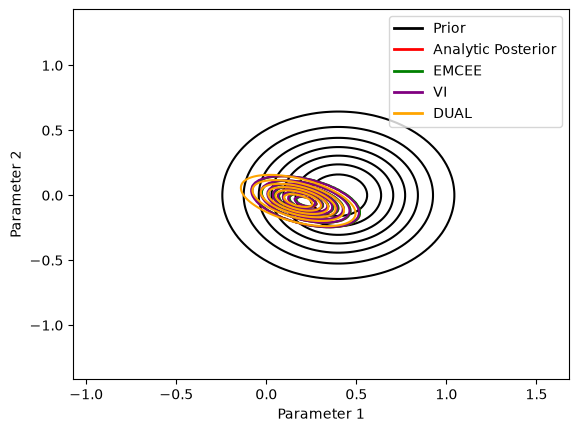

In [6]:
#Tri contour plots

fix,ax = plt.subplots()
#Tri contour plot
rv1 = ss.multivariate_normal(mean=prior_mean, cov=prior_cov)
rv2 = ss.multivariate_normal(mean=mu_posterior, cov=Gamma_posterior)
rv3 = ss.multivariate_normal(mean=emcee_mean, cov=emcee_cov)
rv4 = ss.multivariate_normal(mean=optimized_mu, cov=optimized_covariance)
        
std = np.sqrt(np.diag(prior_cov))


x = np.linspace(prior_mean[0] - 3*std[0], prior_mean[0]+3*std[0], 100)
y = np.linspace(prior_mean[1]- 3*std[1] ,prior_mean[1] + 3*std[1],100)

        
X,Y = np.meshgrid(x,y)
pos = np.dstack((X,Y))

post_pdf1 = np.exp(rv1.logpdf(pos))
post_pdf1[post_pdf1==0] = np.nan
        
post_pdf2 = np.exp(rv2.logpdf(pos))
post_pdf2[post_pdf2==0] = np.nan

post_pdf3 = np.exp(rv3.logpdf(pos))
post_pdf3[post_pdf3==0] = np.nan

post_pdf4 = np.exp(rv4.logpdf(pos))
post_pdf4[post_pdf4==0] = np.nan



plt.tricontour(X.ravel(), Y.ravel(), post_pdf1.ravel(), levels = 8, colors = 'black')
plt.tricontour(X.ravel(), Y.ravel(), post_pdf2.ravel(), levels = 8, colors = 'red')
plt.tricontour(X.ravel(), Y.ravel(), post_pdf3.ravel(), levels = 8, colors = 'green')
plt.tricontour(X.ravel(), Y.ravel(), post_pdf4.ravel(), levels = 8, colors = 'purple')
plt.tricontour(prior_samples_one[:, 0], prior_samples_one[:, 1], semi_analytic_vals, levels =8, colors = 'orange')

legend_lines = [
    Line2D([0], [0], color='black', lw=2, label='Prior'),
    Line2D([0], [0], color='red', lw=2, label='Analytic Posterior'),
    Line2D([0], [0], color='green', lw=2, label='EMCEE'),
    Line2D([0], [0], color='purple', lw=2, label='VI'),
    Line2D([0], [0], color='orange', lw=2, label='DUAL'),
]
plt.xlabel("Parameter 1")
plt.ylabel("Parameter 2")

plt.legend(handles=legend_lines)


fig = plt.gcf()
fig.savefig('Prior_Posterior_Contours_ALL.png', dpi=300, transparent=True, bbox_inches='tight')
plt.show()



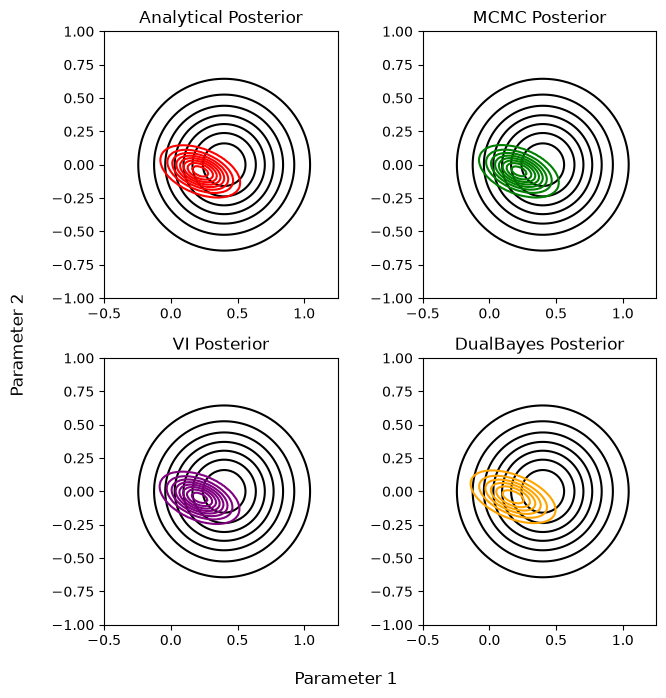

In [7]:
import matplotlib.pyplot as plt

posteriors = [
    (post_pdf2, X.ravel(), Y.ravel(), 'Analytical Posterior'),
    (post_pdf3, X.ravel(), Y.ravel(), 'MCMC Posterior'),
    (post_pdf4, X.ravel(), Y.ravel(), 'VI Posterior'),
    (semi_analytic_vals, prior_samples_one[:,0], prior_samples_one[:,1], 'DualBayes Posterior')
]


fig, axes = plt.subplots(2, 2, figsize=(7, 7))

colors = ['red', 'green', 'purple', 'orange']

# Common limits
#xlim = (
   # min(X.min(), prior_samples_one[:, 0].min()),
    #max(X.max(), prior_samples_one[:, 0].max())
#)


#ylim = (
   # min(Y.min(), prior_samples_one[:, 1].min()),
   # max(Y.max(), prior_samples_one[:, 1].max())
#)

xlim = (-0.5, 1.25)
ylim = (-1,1)

for ax, (posterior, x, y, title), color in zip(axes.flat, posteriors, colors):

    # Prior
    ax.tricontour(
        X.ravel(),
        Y.ravel(),
        post_pdf1.ravel(),
        levels=8,
        colors='black'
    )

    # Posterior
    ax.tricontour(
        x,
        y,
        posterior.ravel(),
        levels=8,
        colors=color
    )

    ax.set_title(title)
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    ax.set_aspect('equal')

fig.supxlabel('Parameter 1')
fig.supylabel('Parameter 2')

plt.tight_layout()
plt.show()

fig.savefig('PriorPosteriorContour.png', dpi=300, transparent=True, bbox_inches='tight')


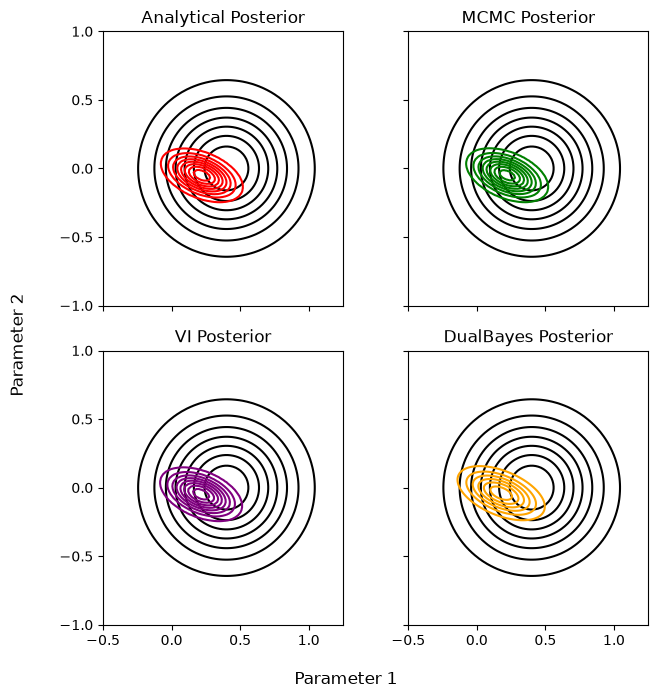

In [9]:
import matplotlib.pyplot as plt

posteriors = [
    (post_pdf2, X.ravel(), Y.ravel(), 'Analytical Posterior'),
    (post_pdf3, X.ravel(), Y.ravel(), 'MCMC Posterior'),
    (post_pdf4, X.ravel(), Y.ravel(), 'VI Posterior'),
    (semi_analytic_vals, prior_samples_one[:,0], prior_samples_one[:,1], 'DualBayes Posterior')
]

fig, axes = plt.subplots(
    2, 2,
    figsize=(7, 7),
    sharex=True,
    sharey=True
)

colors = ['red', 'green', 'purple', 'orange']

xlim = (-0.5, 1.25)
ylim = (-1, 1)

for ax, (posterior, x, y, title), color in zip(
    axes.flat, posteriors, colors
):

    # Prior
    ax.tricontour(
        X.ravel(),
        Y.ravel(),
        post_pdf1.ravel(),
        levels=8,
        colors='black'
    )

    # Posterior
    ax.tricontour(
        x,
        y,
        posterior.ravel(),
        levels=8,
        colors=color
    )

    ax.set_title(title)
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    ax.set_aspect('equal')

# Only show x tick labels on the bottom row
for ax in axes[0, :]:
    ax.tick_params(labelbottom=False)

# Only show y tick labels on the left column
for ax in axes[:, 1]:
    ax.tick_params(labelleft=False)

from matplotlib.ticker import MaxNLocator

# Limit number of y-axis ticks
for ax in axes.flat:
    ax.yaxis.set_major_locator(MaxNLocator(4))

fig.supxlabel('Parameter 1')
fig.supylabel('Parameter 2')

# Reduce the gaps between subplots
plt.tight_layout()

plt.show()

fig.savefig(
    'PriorPosteriorContour.png',
    dpi=300,
    transparent=True,
    bbox_inches='tight'
)

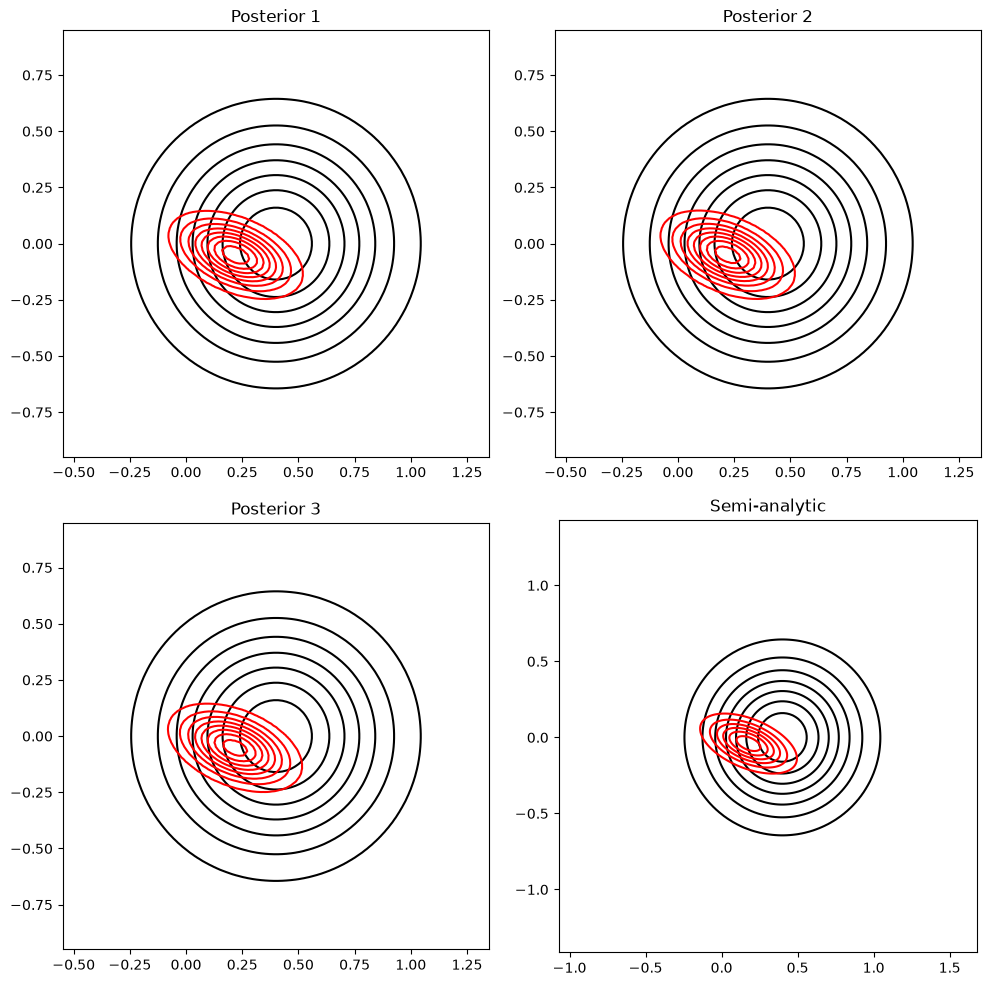

In [14]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(10, 10))

posteriors = [
    (post_pdf2, X.ravel(), Y.ravel(), 'Posterior 1'),
    (post_pdf3, X.ravel(), Y.ravel(), 'Posterior 2'),
    (post_pdf4, X.ravel(), Y.ravel(), 'Posterior 3'),
    (semi_analytic_vals, prior_samples_one[:, 0], prior_samples_one[:, 1], 'Semi-analytic')
]

for ax, (pdf, x, y, title) in zip(axes.flat, posteriors):
    # Prior
    ax.tricontour(
        X.ravel(),
        Y.ravel(),
        post_pdf1.ravel(),
        levels=8,
        colors='black'
    )

    # Posterior
    ax.tricontour(
        x,
        y,
        pdf.ravel(),
        levels=8,
        colors='red'
    )

    ax.set_title(title)
    ax.set_aspect('equal')

plt.tight_layout()
plt.show()

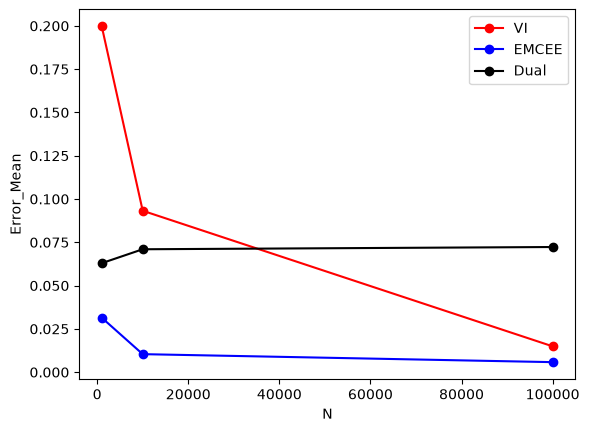

In [22]:
#Error Plot

plt.figure()
plt.plot(N_values_VI, mean_errors_VI, marker = 'o', color = 'red',label = 'VI')
plt.plot(N_values_emcee, mean_errors_emcee, marker = 'o', color = 'blue', label = 'EMCEE')
plt.plot(budgets,mean_errors_dual, marker = 'o', color = 'black', label = 'Dual')
plt.xlabel("N")
plt.ylabel('Error_Mean')
plt.legend()
plt.show()




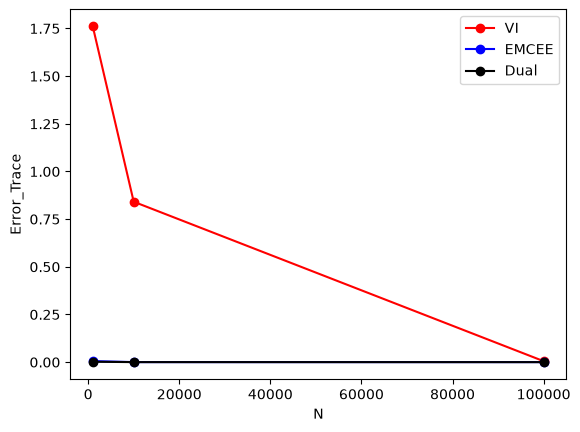

In [23]:
#Trace Plots
plt.figure()
plt.plot(N_values_VI, trace_errors_VI, marker = 'o', color = 'red',label = 'VI')
plt.plot(N_values_emcee, trace_errors_emcee, marker = 'o', color = 'blue', label = 'EMCEE')
plt.plot(budgets,trace_errors_dual, marker = 'o', color = 'black', label = 'Dual')
plt.xlabel("N")
plt.ylabel('Error_Trace')
plt.legend()
plt.show()

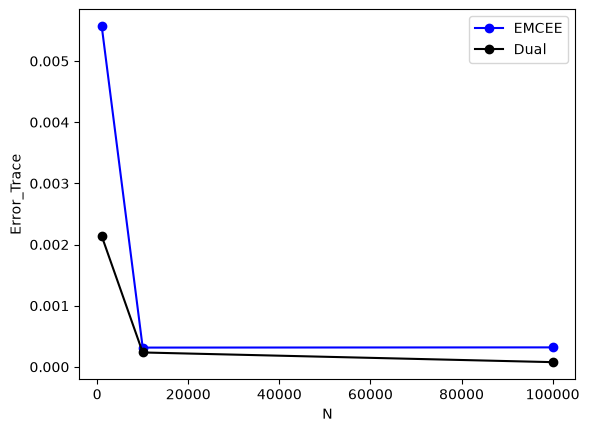

In [24]:
#Trace without VI
plt.figure()
plt.plot(N_values_emcee, trace_errors_emcee, marker = 'o', color = 'blue', label = 'EMCEE')
plt.plot(budgets,trace_errors_dual, marker = 'o', color = 'black', label = 'Dual')
plt.xlabel("N")
plt.ylabel('Error_Trace')
plt.legend()
plt.show()